
# Laboratoire de programmation mathématique 3 :<br/> L'ordre dans l'aléatoire <span style="color:silver">(théorie des probabilités)</span>

## Le paradoxe des anniversaires

Vous avez peut-être déjà entendu cette question : Si nous prenons un groupe de 25 personnes, quelle est la probabilité qu'au moins 2 d'entre elles aient le même anniversaire ?

Il n'est pas difficile de le calculer précisément, mais nous allons utiliser une simulation informatique : Nous choisissons $N$ groupes aléatoires de 25 personnes, où $N$ est très grand. Ensuite, nous déterminons dans combien de ces groupes au moins 2 personnes ont le même anniversaire ; nous notons ce nombre par $K$. Notre estimation de la probabilité sera alors $K/N$.

> Pour simplifier le problème : Nous supposerons que chaque année a 365 jours (en oubliant le 29 février) et que chaque jour de l'année a la même probabilité d'être l'anniversaire d'une personne choisie au hasard.

Comment pouvons-nous faire cela en python ?

Pour obtenir un nombre aléatoire de (0,1,2,...,364) (un anniversaire), nous pouvons utiliser l'une des méthodes ci-dessous (exécutez la cellule) :



In [1]:
### EXÉCUTEZ-MOI

from random import randrange
import numpy as np

print('méthode 1:', randrange(365))

print('méthode 2:', np.random.choice(365))


méthode 1: 356
méthode 2: 17


> Pour obtenir un nombre aléatoire de (1,2,..365), utilisez par exemple `randrange(1, 366)` ou `1 + randrange(365)` - mais nous nous en tiendrons à `randrange(365)`

Pour obtenir une liste (ou un tableau) de 25 anniversaires aléatoires, nous pouvons faire


In [2]:
### EXÉCUTEZ-MOI

# ceci donne une liste
groupe1 = [randrange(365) for i in range(25)]

# ceci donne un tableau numpy et est meilleur pour les grandes tailles
groupe2 = np.random.choice(365, size=25)

print('groupe 1 (une liste):')
print(groupe1)
print()
print('groupe 2 (un tableau numpy):')
print(groupe2)


groupe 1 (une liste):
[196, 342, 13, 58, 314, 246, 66, 289, 300, 185, 104, 162, 37, 56, 326, 94, 173, 223, 344, 169, 217, 103, 285, 201, 144]

groupe 2 (un tableau numpy):
[ 30  97 353 310 179 313 249  68 295 129 288 333 169  19  94 247  54 179
 333 344 140 219 116 129 127]


Comment pouvons-nous  vérifier si deux anniversaires coïncident ? Nous allons en fait calculer combien d'éléments (c'est-à-dire d'anniversaires) _différents_  la liste (ou le tableau) contient. Une option est de transformer la liste/tableau en un _ensemble_ (un type de données spécial en python, `set`) puis de demander combien d'éléments l'ensemble contient, en utilisant la fonction `len` (=longueur). Si moins de 25, au moins 2 anniversaires coïncident.


In [3]:
#### EXÉCUTEZ-MOI

unique1 = set(groupe1)
print('le nombre d\'anniversaires dans le groupe 1:', len(unique1))

unique2 = set(groupe2)
print('le nombre d\'anniversaires dans le groupe 2:', len(unique2))

unique2_alt = np.unique(groupe2)
print('une autre façon d\'obtenir le nombre d\'anniversaires dans le groupe 2:', len(unique2))

le nombre d'anniversaires dans le groupe 1: 25
le nombre d'anniversaires dans le groupe 2: 22
une autre façon d'obtenir le nombre d'anniversaires dans le groupe 2: 22


<div style="border: 1px solid gold; padding: 5px">


**Exercice :**

Réalisez maintenant la simulation. Choisissez un grand $N$, disons 10000, générez $N$ groupes un par un (via une boucle for) et calculez $K$ (le nombre de groupes où au moins 2 personnes partagent le même anniversaire), puis affichez la probabilité estimée $K/N$. Exécutez votre code plusieurs fois pour voir que vous obtenez une réponse différente à chaque fois (c'est une simulation aléatoire !), mais que les réponses sont proches les unes des autres. La probabilité peut sembler étonnamment élevée !

</div>


In [4]:
### ÉCRIVEZ ICI

groupes_anniversaire = [np.random.choice(365, size = 25)for _ in range(10000)]
groupes_en_sets = [set(groupe) for groupe in groupes_anniversaire]

k = 0

for e in groupes_en_sets:
    if len(e)<25:
        k += 1

result = k/len(groupes_en_sets)

print(result)

0.5669


Quelle est la vraie probabilité (non estimée) ? Il y a $365^{25}$ possibilités pour le choix des anniversaires des 25 personnes. Si nous voulons uniquement des groupes où aucun anniversaire n'est identique, nous avons 365 options pour l'anniversaire de la 1ère personne, 364 pour la 2ème personne, ... 365 - 24 pour l'anniversaire de la 25ème personne, donc la probabilité d'avoir au moins 2 anniversaires qui coïncident est


In [5]:
### EXÉCUTEZ-MOI

1 - np.prod([(365 - i)/365 for i in range(25)])

np.float64(0.568699703969464)

## Estimer $\pi$ douloureusement lentement puis un peu plus rapidement

### Nombres aléatoires de $[0,1]$
Pour obtenir un nombre réel aléatoire de l'intervalle $[0,1]$, nous pouvons utiliser ces options :


In [6]:
### EXÉCUTEZ-MOI

from random import random
# cela peut sembler déroutant, mais c'est simple : 
# le module random contient une fonction appelée random
# que nous importons

print('méthode 1:', random())
print('méthode 2:', np.random.random())

méthode 1: 0.7632084794036682
méthode 2: 0.4823157143508662


Comme d'habitude, la force de la fonction numpy est qu'elle peut nous donner un tableau de nombres aléatoires :


In [7]:
### EXÉCUTEZ-MOI

print(np.random.random(5))
print()
print(np.random.random([3, 4]))

[0.774434   0.90145825 0.4972134  0.04456736 0.91441871]

[[0.84482101 0.82593198 0.98681244 0.16368946]
 [0.10110573 0.33377584 0.48977898 0.91233865]
 [0.31605399 0.1663133  0.74453508 0.06224579]]


> Que signifie un "nombre réel aléatoire de $[0,1]$" ? Pour un ordinateur, c'est facile : ses nombres réels ont une précision finie (bien que très élevée), et il vous donnera un nombre de la forme $k/2^{64}$, où $k$ est un entier, $0\leq k<2^{64}$, et il produira chacun de ces nombres avec la même probabilité $2^{-64}$. Si nous exécutons `random()` deux fois et obtenons 2 nombres aléatoires, alors chaque paire de nombres aura également la même probabilité $2^{-128}$. (Les détails sur la façon dont ces nombres aléatoires sont produits et s'ils sont vraiment aléatoires sont plus compliqués et nous n'avons pas besoin de nous en préoccuper dans ce laboratoire.)

### Estimer $\pi$ via des nombres aléatoires

L'image ci-dessous montre $N=10000$ points choisis aléatoirement dans le carré unitaire $[0,1]\times[0,1]$. Combien d'entre eux sont dans la zone jaune ? C'est un nombre aléatoire, mais nous nous attendons à ce qu'il soit autour de $N A$, où $A$ est l'aire de la tache jaune. Cela nous donne une méthode pour calculer approximativement $A$ :
$$A\approx(\text{nombre de points dans la tache}) / N$$

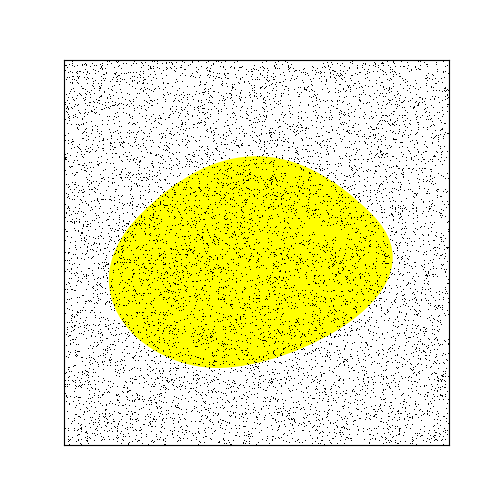



Calculons approximativement $\pi$ en utilisant l'idée décrite ci-dessus, lorsque la tache jaune est un quart de disque (d'aire $\pi/4$), comme dessiné ici :

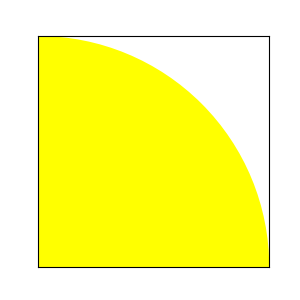

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Écrivez une fonction `rand_pi(N)` qui choisit $N$ fois un point aléatoire $(x,y)$ dans le carré et compte le nombre $K$ de ces points qui sont dans le quart de disque, c'est-à-dire qui satisfont $x^2 +y^2 \leq 1$. Elle renvoie ensuite l'estimation de $\pi$ comme $4 K/N$. Faites-le de la manière la plus simple, par une boucle for `for n in range(N)`, en générant $x$ et $y$ via `random()`, et en augmentant $K$ chaque fois que le point satisfait $x^2 +y^2 \leq 1$.

Puis exécutez votre fonction pour $N = $ 10, 100, 1000, 10000, ... et voyez comment elle se rapproche de $\pi=3.141592\dots$ et que ce n'est pas très rapide (la différence est d'ordre $1/\sqrt N$).

</div>

> Pour interrompre votre fonction (si elle prend trop de temps), appuyez sur le bouton $\blacksquare$ ci-dessus (ou dans le menu : Kernel > Interrupt kernel)



In [ ]:
### ÉCRIVEZ ICI

from numba import njit

@njit
def rand_pi(N):
    k=0

    for i in range(N):
        x = random()
        y = random()

        while x**2+y**2 <=1:
            k+=1
    
    return 4*k/N

print(rand_pi(10))

Nous pouvons  rendre la fonction plus rapide avec numpy :

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Écrivez une fonction `rand_pi_np(N)` qui fait la même chose en utilisant numpy. Créez un tableau des coordonnées $x$ des $N$ points par `x=np.random.random(N)` et de même pour les coordonnées $y$. À partir des tableaux `x` et `y`, calculez un tableau `inside` qui contient, pour chacun des points, `True` si le point est dans le disque et `False` sinon. (Rappel : cela se fait par `x**2 + y**2 <= 1`.) Enfin, déterminez combien de points sont dans le disque (rappel : utilisez `np.sum`;  `True` se comporte comme 1 et `False` comme 0 lorsque nous les additionnons.)

Puis exécutez votre fonction pour $N = $ 10, 100, 1000, 10000, ... - elle s'exécutera espérons-le plus rapidement (numpy est très efficace).
</div>

In [ ]:
### ÉCRIVEZ ICI

def rand_pi_alt(N):

    x = np.random.random(N)
    y = np.random.random(N)
    
    f = x**2+y**2

    k = np.sum(f<=1)

    return 4*k/N

print(rand_pi_alt(10))
print(rand_pi_alt(100))
print(rand_pi_alt(1000))
print(rand_pi_alt(10000))

3.6
3.28
3.116
3.1352



J'espère que c'était facile et compréhensible. Parfois, cependant, il est assez difficile d'écrire un algorithme "à la manière numpy", c'est-à-dire sans aucune boucle `for` ou `while`. (Un autre inconvénient est que numpy crée les grands tableaux `x` et `y`, qui nécessitent beaucoup de mémoire.) Voici comment rendre votre première fonction `rand_pi` rapide sans aucune modification.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Copiez et collez votre fonction `rand_pi` (la définition complète `def rand_pi(N): ...`) en dessous de `@njit` dans la cellule ci-dessous et exécutez la cellule. Ensuite, exécutez dans la cellule suivante `rand_pi(10)` - cela peut prendre un certain temps. Puis essayez `rand_pi(10000000)` - ce sera maintenant peut-être plus rapide que `rand_pi_np`.

</div>

> Quelle est cette sorcellerie ? La syntaxe python (où `@njit` est appelé un "décorateur")
> > ```python
> > @njit
> > def f(x):
> >    return x + 1
> > ```
> 
> est juste un raccourci pour
> 
> >```python
> >def f(x):
> >    return x + 1
> >
> >f = njit(f)
> >```
>
> En d'autres termes, `njit` (importé de `numba`) est une fonction, nous lui fournissons la fonction `f` via `njit(f)`, elle renvoie une autre fonction, et nous appelons le résultat à nouveau `f`, c'est-à-dire que nous remplaçons `f` par la fonction modifiée `njit(f)`. La vraie sorcellerie est ce que fait `njit` - il compile `f` en code machine, qui s'exécute alors vraiment rapidement. La compilation proprement dite se produit lorsque nous exécutons `f` pour la 1ère fois (et peut prendre un peu de temps). `njit` ne compilera pas tout (voir la documentation de Numba si vous voulez des détails), mais il peut être librement combiné avec `numpy`.


In [ ]:
### COLLEZ VOTRE FONCTION rand_pi(N) EN DESSOUS DE @njit ET EXÉCUTEZ LA CELLULE

@njit
def rand_pi(N):
    k=0

    for i in range(N):
        x = random()
        y = random()

        if x**2+y**2 <=1:
            k+=1
    
    return 4*k/N

print(rand_pi(10))


3.2


## Loi des grands nombres et Théorème central limite

### Loi des grands nombres

Nous lançons un dé $N$ fois, où $N$ est un nombre très grand. À chaque fois, nous obtenons un nombre entre 1 et 6. Quelle est la moyenne de ces $N$ nombres ? Nous ne le savons pas (ce pourrait être 1 si nous avons obtenu 1 à chaque fois, mais c'est hautement improbable), mais voici ce à quoi nous pourrions nous attendre : nous obtenons 1 environ $N/6$ fois, 2 environ $N/6$ fois..., donc la moyenne devrait être, avec une probabilité élevée, environ
$$\frac{1+2+\dots+6}6 =3.5$$

Plus généralement (lorsque nous remplaçons le dé par autre chose), si nous obtenons à chaque "lancer" une valeur $v$ avec une probabilité $p_v$, et si nous répétons de nombreuses fois, nous nous attendons à ce que la moyenne des valeurs obtenues soit, avec une probabilité élevée, proche de
$$\sum_v v\, p_v.$$
C'est la _loi des grands nombres_ (vous verrez un énoncé précis dans votre cours de probabilités).

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Écrivez les fonctions `dice_mean(N)` et `dice_mean_np(N)` qui lancent un dé `N` fois et calculent la moyenne.
La 1ère fonction devrait utiliser une boucle for, rendez-la rapide avec `@njit`. La 2ème devrait utiliser numpy (et pas de boucles)
>  au lieu de `np.sum()`, vous pouvez utiliser `np.mean()` pour obtenir directement la moyenne.

Ensuite, exécutez vos fonctions pour `N = 1_000_000` 5 fois (utilisez une boucle for et `print`)) et voyez ce qu'elles donnent.
</div>

In [ ]:
### ÉCRIVEZ ICI

@njit
def dice_mean(N):
    tirages = 0

    for i in range(N):
        tirages += random.randint(1, 6)

    return tirages / N

print(dice_mean(1_000_000))


3.500113


In [ ]:
def dice_mean_np(N):
    tirages = np.random.randint(1, 7, size= N)

    return tirages.mean()

print(dice_mean_np(1_000_000))


3.497772


Si tout s'est bien passé, les valeurs sont proches de 3.5. Mais pouvons-nous dire quelque chose de plus précis que "proche" ? Faisons plus d'expériences !

Comment pourrions-nous exécuter `dice_mean(N)` `k` fois (pour un grand nombre `k`) et enregistrer les résultats dans une liste ou un tableau numpy ? Une option est
```python
[dice_mean(N) for i in range(k)]
```
(ou un code similaire avec une boucle for). Cela pourrait être un peu lent si à la fois `N` et `k` sont grands. Voici ce que nous pouvons faire pour le rendre rapide.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Modifiez légèrement votre fonction `dice_mean_np(N)` : Au lieu de calculer la moyenne via `np.mean(your_array)`, utilisez `np.mean(your_array, axis=0)`. Elle fonctionnera maintenant aussi pour les tableaux à 2 dimensions, calculant les moyennes le long du premier axe et stockant les résultats dans un tableau à 1 dimension (le 1er axe correspond à `axis=0` ; en python, tout est compté à partir de 0). Exécutez `dice_mean_np([1000, 5])` pour vérifier si cela fonctionne (cela correspond à N=1000 et k=5). Assurez-vous de comprendre ce qui se passe.
</div>

In [ ]:
def dice_mean_np(N):
    tirages =np.random.randint(1, 7, size= N)

    return np.mean(tirages, axis=0)

print(dice_mean_np([1000, 5]))

[3.461 3.518 3.504 3.515 3.472]


Faisons-le aussi en modifiant un peu `dice_mean(N)`. Nous allons le faire différemment. Pour le moment, `N` doit être un entier. Nous allons modifier la fonction pour que `N` puisse être un tableau d'entiers : elle appliquera le `dice_mean` original à chaque élément du tableau, et renverra les résultats sous forme de tableau (de même taille).

> Cela le rendra pareil à beaucoup de fonction numpy, t.q. `np.cos`: is `x` est un nombre, `np.cos(x)` calcule son cosinus; si `x` est un tableau, `np.cos(x)` calcule les cosinus de tous les éléments de `x`.




<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Modifiez votre fonction `dice_mean(N)` comme suit : importez de `numba` la fonction `vectorize` et changez le décorateur `@njit` en `@vectorize(nopython=True)` (l'option `nopython=True` assure simplement que le code compilé est très rapide). Maintenant, elle accepte les tableaux numpy (c'est à cela que sert `vectorize`). En l'utilisant, définissez ci-dessous une fonction `dice_mean_k(N, k)`, qui renvoie la même chose que `dice_mean_np([N, k])` ferait. Exécutez `dice_mean_k(1000, 5)` pour vérifier que cela fonctionne.
</div>

> Pour la dernière chose, vous devez fournir à `dice_mean` un tableau de longueur `k`, contenant uniquement des `N`. Vous pouvez obtenir un tel tableau via `np.array([N for i in range(k)])`, ou via `np.array(k * [N])`, ou (l'option la plus rapide et la "meilleure") via `N * np.ones(k, dtype=np.int64)` (l'option `dtype=np.int64` est quelque peu facultative (`dtype` signifie "type de données") - elle garantira que le tableau contient des entiers et non des `float`).


**Un conseil important sur l'utilisation de numba:**
Comme numba compile les fonctions en code machine, les messages d'erreur peuvent être difficiles à comprendre. C'est une bonne idée de tester d'abord vos fonctions sans numba (bien qu'elles soient beaucoup plus lentes) et d'ajouter les décorateurs numba seulement après cela. Utilisez le décorateur `@np.vectorize` comme un remplacement sûr (mais lent) de `@vectorize(nopython=True)` pour les tests. Si, à la fin, vous n'êtes pas capable de faire fonctionner vos fonctions avec numba, utilisez la version lente (vous devrez diminuer les arguments) - mais faites de votre mieux (et demandez de l'aide) avant cela. 



In [ ]:
### ÉCRIVEZ ICI

from numba import vectorize

@vectorize(['float64(int64)'], nopython=True)
def dice_mean(N):
    tirages = 0

    for i in range(N):
        tirages += random.randint(1, 6)

    return tirages/N

In [2]:
def dice_mean_k(k, N):
    tableau_N = N*np.ones(k, dtype=np.int64)

    return dice_mean(tableau_N)

Testons votre nouvelle fonction `dice_mean` et la loi des grands nombres :


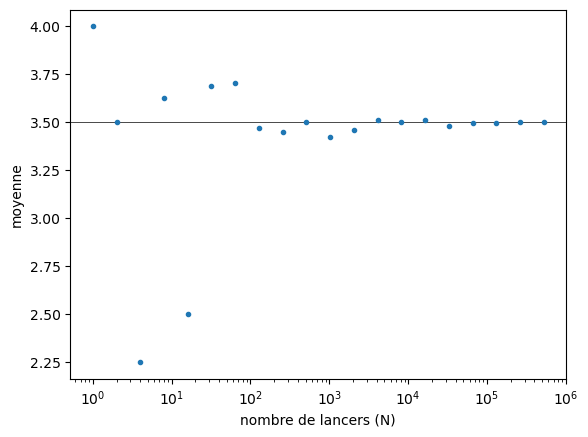

In [ ]:
### EXÉCUTEZ-MOI

import numpy as np
import matplotlib.pyplot as plt

N = np.array([2**p for p in range(20)], dtype=np.int64)
plt.axhline(3.5, color='k', linewidth=0.5)
plt.plot(N, dice_mean(N), '.')
plt.xlabel('nombre de lancers (N)')
plt.ylabel('moyenne')
plt.xscale('log')

### Théorème central limite

Maintenant que vous avez votre code prêt, voyons comment les moyennes `dice_mean(N)` sont distribuées autour de la moyenne attendue 3.5.
Exécutez la cellule ci-dessous. Elle montre où se trouvent les `k = 100_000` valeurs produites par `dice_mean(N)`. Le graphique s'appelle un _histogramme_ - plus il est haut, plus il y a de valeurs. Plus précisément, l'aire de chacun de ces rectangles bleus est la proportion des `k` moyennes qui tombent dans l'intervalle correspondant.
> L'aire totale de tous les rectangles est 1 - c'est ce que fait l'option `density=True` (sans elle, la hauteur de chaque rectangle serait le nombre de points de données dans l'intervalle correspondant). L'option `bins=50` crée 50 rectangles.


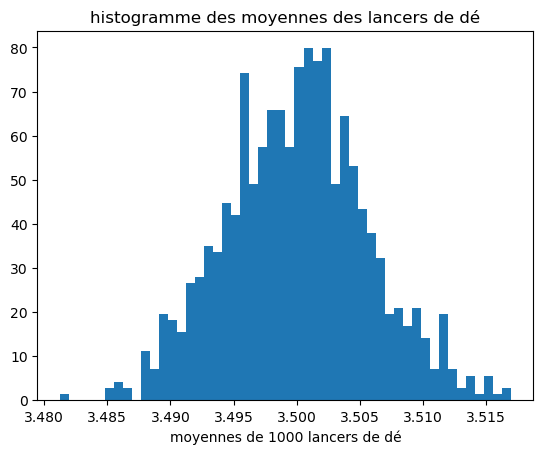

In [ ]:
### EXÉCUTEZ-MOI

import matplotlib.pyplot as plt

N = 1000
k = 100_000

plt.hist(dice_mean_k(N, k), bins=50, density=True)
plt.xlabel(f'moyennes de {N} lancers de dé')
plt.title('histogramme des moyennes des lancers de dé')

plt.show()


Qu'est-ce que cette courbe en forme de cloche que nous avons obtenue ? Elle est décrite par le *théorème central limite*. Discutons-en en détail. La courbe est centrée autour de la moyenne théorique (appelée *espérance* en théorie des probabilités), donnée par
$$\mu = \sum_v v\,p_v.$$
En d'autres termes, les moyennes réelles $m$ de $N$ lancers sont proches de l'espérance $\mu$.
Dans notre cas, $\mu =\sum_{v=1}^6 v\, \frac16 =3.5$.

Quelle est la largeur de la courbe ? En d'autres termes, à quelle distance de $\mu$ se trouvent typiquement les moyennes $m$ ? Comme nous l'avons brièvement mentionné ci-dessus, la largeur est proportionnelle à $1/\sqrt N$. Mais nous pouvons être plus précis maintenant : elle est donnée par $\sigma/\sqrt N$, où $\sigma$, appelé *écart-type*, est définie par
$$\sigma^2 = \sum_v (v-\mu)^2\, p_v.$$
Et maintenant, le véritable contenu du théorème central limite. Transformons $m$ en une nouvelle valeur $x$ via
$$m = \mu + \frac{\sigma}{\sqrt N}\, x.$$
Nous le faisons parce que maintenant les $x$ sont centrés autour de 0 et leur "dispersion" est de 1. Le théorème central limite affirme alors que l'histogramme des $x$ est approximativement (et avec une forte probabilité) donné par la *distribution normale*
$$\frac1{\sqrt{2\pi}}\,\exp(-x^2/2)$$
La loi des grands nombres et le théorème central limite sont les résultats les plus utiles en théorie des probabilités appliquée.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Dessinez l'histogramme des $x$ (copiez le code de la cellule ci-dessus et modifiez-le - vous devrez calculer le tableau contenant les $x$). Tracez sur la même figure également le graphe de la distribution normale, pour $-4 \leq x \leq 4$.
</div>

> ajoutez votre code au-dessus de la commande `plt.show()`, afin que le graphique soit dessiné sur la même image que l'histogramme

In [3]:
### ÉCRIVEZ ICI

N = 1000
k = 100_000

moyennes = dice_mean_k(N, k)

mu = 3.5
sigma = np.sqrt(35 / 12)
x = (moyennes - mu) / (sigma / np.sqrt(N))

plt.hist(x, bins=50, density=True)

x_norm = np.linspace(-4, 4, 1000)
y_norm = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x_norm**2)
plt.plot(x_norm, y_norm, 'r-', lw=2)

plt.show()

NameError: name 'np' is not defined


## Temps d'attente et autres surprises

### Attendre un 6

Combien de fois, en moyenne, devons-nous lancer un dé jusqu'à obtenir un 6 ? Votre intuition dira probablement 6, et c'est correct.

Quel est le nombre le plus probable de fois que nous devons lancer un dé jusqu'à obtenir un 6 ?

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Créez une fonction `roll_till_6(N)` qui lance un dé jusqu'à obtenir un 6, répète cela `N` fois, écrit les `N` résultats (le nombre de lancers) dans un tableau numpy de longueur `N` et renvoie le tableau. Testez votre fonction pour un petit `N`.
</div>

> Ma suggestion est de commencer avec un tableau contenant des 0, que vous obtenez via `np.zeros(N, dtype=np.int64)` (ou avec un tableau de 1 `np.ones(N, dtype=np.int64)`, selon votre algorithme). Ensuite, écrivez une boucle `for i in range(N)`. Rappel : pour obtenir le i-ème élément d'un tableau `a`, utilisez `a[i]`. Accélérez votre fonction en mettant le décorateur `@njit` au-dessus.


In [ ]:
### ÉCRIVEZ ICI

def roll_till_6(N):
    resultats = np.zeros(N, dtype=np.int64)

    for i in range(N):
        lancers = 0

        while True :
            lancers += 1
            tirage = np.random.randint(1, 7)

            if tirage == 6:
                resultats[i] = lancers
                break
            
    return resultats



In [ ]:
petit_N = 10
print(roll_till_6(petit_N))

[13  1  7  6  1 11  1  5 10  1]


Vérifions ce qui se passe pour `N = 100_000`. D'abord, calculons le temps d'attente moyen (nombre moyen de lancers nécessaires pour obtenir un 6) :


In [ ]:
### EXÉCUTEZ-MOI

N = 100_000
print("temps moyen jusqu'à ce que nous obtenions un 6:", np.mean(roll_till_6(N)))

temps moyen jusqu'à ce que nous obtenions un 6: 6.02545


Espérons que ce n'était pas loin de 6.
> Pourquoi est-ce en fait 6 ? Désignons le temps d'attente moyen par $T$. Nous avons toujours besoin d'au moins un lancer. Avec une probabilité de 5/6, nous n'obtenons pas de 6, et dans ce cas, nous devons continuer - le processus recommence. Cela nous donne
$$T = 1 + \frac56\,T$$ et donc $T=6$.

Estimons maintenant les probabilités (pas seulement la _moyenne_ du temps d'attente).
> Si `a` est un tableau contenant des entiers non négatifs, `frequencies = np.bincount(a)` est un nouveau tableau, tel que `frequencies[i]` est le nombre d'occurrences de `i` dans `a`. Pour nous, cela calcule combien de fois (sur N) nous avons obtenu le temps d'attente `i`.


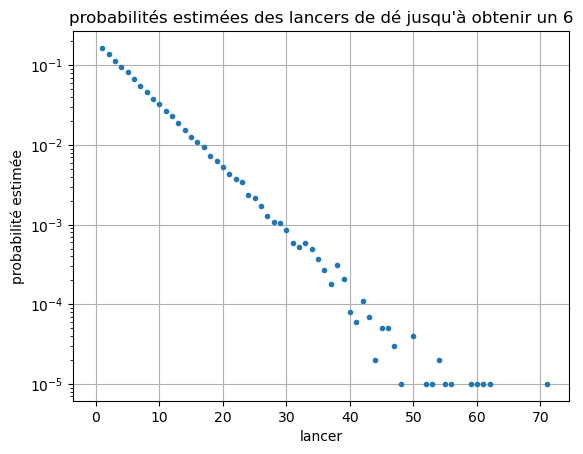

In [ ]:
### EXÉCUTEZ-MOI

N = 100_000

frequencies = np.bincount(roll_till_6(N))
probs = frequencies / N
plt.plot(probs, '.')
plt.yscale('log')
plt.xlabel('lancer')
plt.ylabel('probabilité estimée')
plt.grid()
plt.title('probabilités estimées des lancers de dé jusqu\'à obtenir un 6')
plt.show()



Comme nous le voyons sur le graphique, le temps d'attente 1 a la plus grande probabilité (l'axe $y$ du graphique utilise une échelle logarithmique, car la probabilité estimée diminue très rapidement). En fait, pour chaque $i\geq1$, la probabilité est 
$$p_i = \Bigl(\frac56\Bigr)^{i-1}\frac16$$
(nous devons obtenir $i-1$ fois autre chose que 6, puis une fois 6).

Au lieu de lancer un dé, lançons une pièce. Nous pouvons le modéliser avec `randrange(2)` ou avec `np.random.choice(2)`, qui renvoient 0 ou 1 avec des probabilités égales.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Quel est le temps d'attente moyen jusqu'à ce que nous obtenions deux 1 consécutifs ? \
(Si nos lancers nous ont donné 1001011|100... alors le temps d'attente était de 7, comme indiqué par la barre.) \
Exécutez une simulation.
</div>

In [ ]:
### ÉCRIVEZ ICI

@njit
def deux_1_cons(N):
    total_lancers = 0

    for i in range(N):
        compteur_lancers = 0
        uns_cons = 0

        while True:
            compteur_lancers +=1
            tirage = np.random.randint(0, 2)

            if tirage == 1:
                uns_cons += 1
            
            else:
                uns_cons = 0
            
            if uns_cons == 2:
                total_lancers += compteur_lancers
                break
    
    return total_lancers/N

In [ ]:
N_essais = 1_000_000
print(deux_1_cons(N_essais))

6.00664


La réponse correcte est encore 6 - pouvez-vous voir pourquoi ? (C'est un peu plus difficile !)

### Attendre jusqu'à ce que nous revenions à l'égalité (ou : temps de retour)

Étudions maintenant le temps de retour dans une marche aléatoire. Nous commençons à la position 0, puis chaque seconde, nous faisons un pas, soit en avant, soit en arrière, tous deux avec une probabilité de 1/2. Combien de temps devons-nous attendre avant de revenir à la position de départ ?
> Vous pourriez vous inquiéter de peut-être ne jamais revenir. Heureusement, on peut démontrer qu'avec une probabilité de 1, nous revenons - bien que cela puisse prendre un certain temps.

<div style="border: 1px solid gold; padding: 5px">

**Exercice**

Écrivez une fonction `ret_time(cutoff)` (où `cutoff` sera un grand entier) qui commence une marche aléatoire et renvoie le nombre de pas nécessaires pour revenir à 0. Si la marche ne revient pas dans les `cutoff` pas, la fonction devrait simplement renvoyer `cutoff` (pour que nous n'ayons pas à attendre trop longtemps). Décorez la fonction avec `@vectorize(nopython=True)` pour la rendre rapide et applicable sur des tableaux. Essayez la fonction quelques fois - elle devrait toujours renvoyer un entier pair $\geq 2$.
</div>

> Pour obtenir aléatoirement 1 ou -1, utilisez par exemple `2 * randrange(2) - 1`


In [ ]:
### ÉCRIVEZ ICI

@vectorize(nopython=True)
def ret_time(cutoff):
    position = 0

    for pas in range(1, cutoff + 1):
        mouvement = 2*random.randrange(2)-1
        position += mouvement

        if position == 0:
            return pas
    
    return cutoff

In [ ]:
for i in range(5):
    print(ret_time(1000))

20
4
2
10
2


Utilisons maintenant votre fonction pour estimer les probabilités des temps de retour (c'est-à-dire : avec quelle probabilité revenons-nous après 2 pas ? après 4 pas ? ...). Pour ce faire, nous devons l'exécuter `N` fois, où `N` est un nombre très grand. Comme votre fonction est vectorisée (c'est-à-dire qu'elle peut être appliquée sur des tableaux), nous lui fournissons simplement un tableau constant de taille `N`.


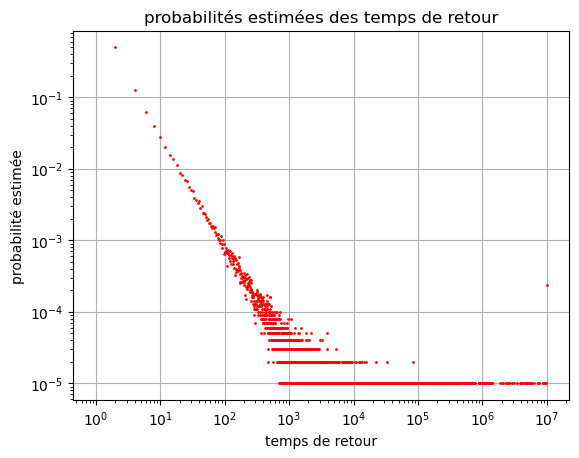

In [ ]:
### EXÉCUTEZ-MOI
### PEUT PRENDRE UN PEU DE TEMPS

N = 100_000
cutoff = 10**7

cutoff_arr = cutoff * np.ones(N, dtype=np.int64)

wait_times = ret_time(cutoff_arr)

frequencies = np.bincount(wait_times)
probs = frequencies / N
plt.plot(probs, 'r.', markersize=2)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('temps de retour')
plt.ylabel('probabilité estimée')
plt.grid()
plt.title('probabilités estimées des temps de retour')
plt.show()


Si tout s'est bien passé, vous devriez voir d'après la pente que la probabilité est à peu près proportionnelle à $1/n^{3/2}$ (pour les grands temps de retour $n$, nous n'avions pas assez de données, donc elle se disperse).\
Vous devriez également voir que $10^7$ avait une probabilité relativement élevée (environ 0,0003) - c'était notre limite (ces marches n'ont pas encore atteint l'origine).\
De manière quelque peu surprenante, la moyenne théorique (appelée _espérance_ en théorie des probabilités) des temps de retour est $\infty$, puisque $\sum_n n/n^{3/2} = \sum_n 1/\sqrt{n}=\infty$.

### La marche aléatoire est étrange

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

- Écrivez les fonctions `positive(n)` et `last_zero(n)`. Toutes deux doivent exécuter une marche aléatoire avec `n` pas. La première doit renvoyer le temps total que la marche aléatoire a passé dans les nombres positifs et la seconde doit renvoyer la dernière fois où la marche aléatoire était à la position 0. Encore une fois, décorez-les avec `@vectorize(nopython=True)` pour les rendre rapides et applicables sur des tableaux.
> Il pourrait être judicieux de tester ces fonctions (avec des `n` pas trop grands) avant de les décorer - une fois qu'elles sont compilées en code machine, les messages d'erreur peuvent devenir cryptiques.\
> Pour obtenir une vitesse encore plus élevée, utilisez le décorateur `@vectorize("int64(int64)", target='parallel', nopython=True)` - votre fonction exécutera plusieurs marches aléatoires en parallèle (si le processeur le permet). (Pour cela, nous devons indiquer au décorateur le type de l'argument et de la valeur renvoyée - c'est ce que fait `"int64(int64)"`.)
- En utilisant ce que vous avez vu jusqu'à présent : définissez `n = 10_000` (la longueur de la marche aléatoire) et simulez `N = 100_000` marches aléatoires : créez un tableau de longueur `N` contenant les valeurs aléatoires `positive(n)`, et un autre tableau contenant les valeurs aléatoires `last_zero(n)`. Divisez les deux tableaux par `n` - leurs éléments seront maintenant entre 0 et 1
- Dessinez l'histogramme des deux tableaux (vous pouvez utiliser `bins=100`). Dessinez également la densité de probabilité théorique pour un très grand $n$ (la même pour les deux histogrammes) $$\frac1{\pi\, \sqrt{x(1-x)}}$$ pour $0< x< 1$ (appelée la _loi de l'arcsinus_).
 > Cette fonction diverge à 0 et 1, alors utilisez `plt.ylim(0, 7)` pour ne voir que la partie pertinente du graphique
</div>

In [ ]:
### ÉCRIVEZ ICI

@vectorize("int64(int64)", target='parallel', nopython=True)
def positive(n):
    position = 0
    temps_positif = 0

    for _ in range(n):
        position_precedente = position
        mouvement = 2 * random.randrange(2) - 1
        position += mouvement

        if position > 0 or position_precedente > 0:
         temps_positif += 1

    return temps_positif

@vectorize("int64(int64)", target='parallel', nopython=True)
def last_zero(n):
    position = 0
    dernier_z = 0
    
    for pas in range(1, n + 1):
        mouvement = 2 * random.randrange(2) - 1
        position += mouvement
        
        if position == 0:
            dernier_z = pas
            
    return dernier_z

NameError: name 'vectorize' is not defined

In [ ]:
n = 10_000
N = 100_000

tableau_n = np.full(N, n, dtype=np.int64)

resultats_positive = positive(tableau_n) / n
resultats_last_zero = last_zero(tableau_n) / n

plt.figure(figsize=(10, 6))

plt.hist(resultats_positive, bins=100, density=True, alpha=0.5)
plt.hist(resultats_last_zero, bins=100, density=True, alpha=0.5)

x = np.linspace(0.001, 0.999, 1000)
y = 1 / (np.pi * np.sqrt(x * (1 - x)))
plt.plot(x, y, 'r-', lw=2)

plt.ylim(0, 7)
plt.xlim(0, 1)

plt.title("Simulation de la loi de l'arcsinus")
plt.grid(True, alpha=0.3)

plt.show()

NameError: name 'positive' is not defined

Ce comportement est assez étrange - par la loi des grands nombres, on pourrait s'attendre à ce qu'une très longue marche aléatoire passe environ la moitié de sa durée dans les nombres positifs. De plus, qui s'attendrait à ce que le dernier passage par 0 se produise le plus probablement soit au début, soit à la fin de la marche ?
> La loi des grands nombres ne s'applique pas ici, car l'espérance (moyenne théorique) des temps de retour est infinie. Vous en apprendrez plus dans votre cours de probabilités.

Pouvez-vous penser à une raison pour laquelle ces deux histogrammes se ressemblent ? C'est une belle énigme !


## Une pause amusante : le cercle arctique

Vous avez travaillé dur, alors maintenant une petite pause où tout est déjà fait.

Comme vous l'avez probablement remarqué, en théorie des probabilités, nous voulons savoir _ce qui se passe avec une très haute probabilité_ (par exemple, vos histogrammes étaient, avec une très haute probabilité, proches des prédictions théoriques). Voici un joli problème de probabilité. Considérons tous les pavages d'un carré par des dominos (rectangles $2\times 1$), comme sur cette image.


<img src="attachment:a759a118-109f-487d-b313-0a207ad328cf.png" width="300">


On peut montrer qu'il y a $2^{n(n+1)/2}$ pavages de ce type, où $n$ est le nombre de "marches" sur le carré, dans ce cas $n=4$. C'est beaucoup, surtout si $n$ est grand.

Que devrions-nous faire si nous voulons générer un pavage aléatoire, où chaque pavage a la _même probabilité_ ? Énumérer tous les pavages est impossible pour un ordinateur (il y en a trop !), mais dans ce cas, il existe un algorithme qui le fait.
> Le tableau `full_board` dans la fonction `generate_tiling` contient tous les centres possibles de dominos placés sur le carré. Il contient `True` si un domino est effectivement à la position et `False` sinon. Pour créer une image à partir de cela, nous utilisons la bibliothèque PIL, qui est un peu plus rapide pour ce genre de tâches que matplotlib




In [ ]:
### EXÉCUTEZ-MOI

import numpy as np
from numba import njit

@njit
def rand_square():
    res = np.eye(2, dtype=np.bool_)
    if np.random.choice(2):
        res = ~res
    return res


# une fonction pour générer un pavage aléatoire
@njit
def generate_tiling(size):
    full_board = np.zeros((2*size, 2*size), dtype=np.bool_)
    for n in range(1, size + 1):
        board = full_board[size-n:size+n, size-n:size+n]
        for i in range(n):
            for j in range(n):
                loc_square = board[2*i:2*i+2, 2*j:2*j+2]
                loc_tot = np.sum(loc_square)
                if loc_tot == 0:
                    board[2*i:2*i+2, 2*j:2*j+2] = rand_square()
                if loc_tot == 1:
                    board[2*i:2*i+2, 2*j:2*j+2] = np.flip(loc_square)
                if loc_tot == 2:
                    board[2*i:2*i+2, 2*j:2*j+2] = np.zeros((2, 2), dtype=np.bool_)                 
    return full_board



# une fonction pour dessiner le pavage

from PIL import Image, ImageDraw
from IPython.display import display

def create_domino_image(r, file_name="domino_tiling.png"):

    # Déterminer la taille de l'image.
    n = r.shape[0]
    width, height = (4 * n + 1, 4 * n + 1)  
    
    # Créer une image blanche vierge.
    img = Image.new('RGB', (width, height), 'white')
    draw = ImageDraw.Draw(img)
    
    # Définir les couleurs.
    red = (255, 0, 0)
    blue = (173, 216, 230)
    black = (0, 0, 0)
    
    # Parcourir toutes les positions True.
    for i, j in np.argwhere(r):
        if (i + j) % 2 == 1:
            # Cas pair : domino horizontal.
            x = (i + j - 2) * 2 + 2
            y = (i - j - 1) * 2 + 2 * n 
            rect_color = blue
            rect_size = (x, y, x + 8, y + 4)
        else:
            # Cas impair : domino vertical.
            x = (i + j - 1) * 2 + 2
            y = (i - j - 2) * 2 + 2 * n 
            rect_color = red
            rect_size = (x, y, x + 4, y + 8)
        
        # Dessiner le rectangle.
        draw.rectangle(rect_size, fill=rect_color, outline=black)
    
    # Sauvegarder l'image.
    img.save(file_name)
    print(f"Image sauvegardée sous {file_name}")
    
    # Afficher l'image dans le Notebook Jupyter.
    display(img)

Maintenant essayez
```
create_domino_image(generate_tiling(5))
```
(La première exécution peut être lente, car @njit doit compiler les fonctions.) Cette image est un peu petite. Mais ensuite remplacez 5 par 100 et essayez à nouveau. Vous pouvez remplacer 100 par 200 si votre ordinateur n'est pas trop lent (cela donnera une image plus convaincante).



Image sauvegardée sous domino_tiling.png


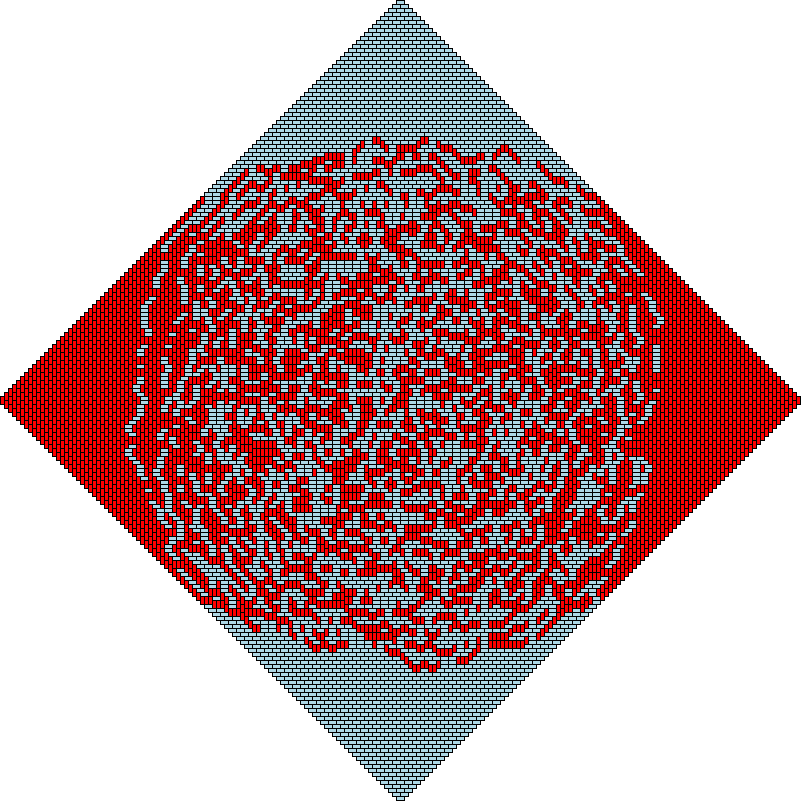

In [ ]:
### EXÉCUTEZ-MOI, PUIS CHANGEZ 5 EN 100 ET EXÉCUTEZ-MOI À NOUVEAU

create_domino_image(generate_tiling(100))

Vous pouvez voir (avec une probabilité extrêmement élevée) un disque. Est-ce que cela signifie que tous les pavages du carré ont cette propriété ? Pas du tout ! Il y en a _beaucoup_ qui ont un aspect complètement différent. Mais le _théorème du cercle arctique_ affirme qu'avec une très haute probabilité, vous obtenez un disque, en d'autres termes, qu'une très grande majorité de pavages ont cette propriété.

## Un générateur (pas trop intelligent) de texte en anglais

### Un peu de python : dictionnaires et compteurs

Apprenons 3 structures de données supplémentaires en python. D'abord, un dictionnaire :


In [ ]:
### EXÉCUTEZ-MOI

# voici comment créer un dictionnaire
d ={'one':'un', 'two':'deux', 'three': 'trois'}

print(d['two'])
print()

# et voici comment vous pouvez le modifier
d['four'] = 4
del d['three']
d['two'] = 'dva'
print(d)
print()

# et comment nous pouvons le parcourir
for key in d:
    print(key, '->', d[key])
print()

# est-ce que 'five' est parmi les clés ?
print('five' in d)
print()

# que se passe-t-il si nous utilisons une mauvaise clé
print('ceci va générer une erreur:')
print(d['five'])

deux

{'one': 'un', 'two': 'dva', 'four': 4}

one -> un
two -> dva
four -> 4

False

ceci va générer une erreur:


KeyError: 'five'

Les _valeurs_ stockées dans un dictionnaire (obtenues via `d[key]`) peuvent être des objets python arbitraires. D'autre part (pour des raisons d'implémentation), les _clés_ ne devraient être que des objets immuables (objets qui ne peuvent pas être modifiés) - cela inclut les chaînes de caractères et les nombres, mais pas les listes ou les dictionnaires.

Cela peut être gênant, mais python a une forme immuable de listes, qui sont appelées _tuples_. Et ceux-ci peuvent être utilisés comme clés (plus précisément : les tuples peuvent être utilisés comme clés si tous leurs éléments sont également immuables).


In [ ]:
### EXÉCUTEZ-MOI

# ceci est un tuple
t = (3, 'one', 9)

print('t[0]:', t[0])
print()

# comment obtenir un tuple avec un seul élément ? 
t1 = (3,)
print('t1:', t1)
print()

# un autre tuple
tt = (7, t)

# leur concaténation
ttt = t + tt
print('ttt:', ttt)
print()

# un sous-tuple ('slice') de ttt, contenant les t[i] avec 2 <= i < 4
t_slice = ttt[2:4]
print('ttt[2:4]:', t_slice)
print()


# nous pouvons les utiliser comme clés de dictionnaires
d = {t:'a', tt:ttt}
print(d)
print()

# de cette façon, vous pouvez convertir une liste en tuple
lst = [2, 1, 6, 'a']
tlst = tuple(lst)
print(tlst)
print()

# nous ne pouvons pas modifier les entrées :
print('ceci va générer une erreur:')
t[1] = 1

t[0]: 3

t1: (3,)

ttt: (3, 'one', 9, 7, (3, 'one', 9))

ttt[2:4]: (9, 7)

{(3, 'one', 9): 'a', (7, (3, 'one', 9)): (3, 'one', 9, 7, (3, 'one', 9))}

(2, 1, 6, 'a')

ceci va générer une erreur:


TypeError: 'tuple' object does not support item assignment

La dernière structure de données est une version spéciale de dictionnaire, utilisée pour compter. Elle s'appelle Counter.


In [ ]:
### EXÉCUTEZ-MOI

from collections import Counter

# une liste avec des répétitions
data = ['one', 1, 'two', 'one', 2, 2, 2, 3, 1, 2]

# créer un Counter qui compte les objets dans la liste `data`
c = Counter(data)

print('voici c:')
print(f'{c = }')

print("combien de fois 'one' apparaît dans la liste `data`?")
print(f"{c['one'] = }")

print("paires (élément, c[élément]), dans l'ordre décroissant")
print(f'{c.most_common() = }')

print("la même chose, mais seulement les 3 éléments les plus fréquents")
print(f'{c.most_common(3) = }')

print("extraire le nombre d'occurrences dans l'ordre décroissant")
print(f'{[x[1] for x in c.most_common()] = }')

voici c:
c = Counter({2: 4, 'one': 2, 1: 2, 'two': 1, 3: 1})
combien de fois 'one' apparaît dans la liste `data`?
c['one'] = 2
paires (élément, c[élément]), dans l'ordre décroissant
c.most_common() = [(2, 4), ('one', 2), (1, 2), ('two', 1), (3, 1)]
la même chose, mais seulement les 3 éléments les plus fréquents
c.most_common(3) = [(2, 4), ('one', 2), (1, 2)]
extraire le nombre d'occurrences dans l'ordre décroissant
[x[1] for x in c.most_common()] = [4, 2, 2, 1, 1]


### Fréquences des mots et la loi de Zipf
Chargeons le livre "Guerre et Paix" comme une liste de mots. Toute la ponctuation est supprimée, à l'exception des ".", qui sont traités comme des mots.\
**Vous devez télécharger le fichier wap.txt depuis le dossier TP3.**
  


In [ ]:
### EXÉCUTEZ-MOI

### UNCOMMENT IF YOU USE GOOGLE COLAB AND UPLOAD THE FILE WHEN ASKED ###
# from google.colab import files
# files.upload_file('wap.txt')

with open('wap.txt', 'r', encoding='utf-8') as f:
    text = f.read()

text = text.split()

text[:20]

['CHAPTER',
 'I',
 'WELL',
 'PRINCE',
 'SO',
 'GENOA',
 'AND',
 'LUCCA',
 'ARE',
 'NOW',
 'JUST',
 'FAMILY',
 'ESTATES',
 'OF',
 'THE',
 'BUONAPARTES',
 '.',
 'BUT',
 'I',
 'WARN']

<div style="border: 1px solid gold; padding: 5px">


**Exercice :**

- Utilisez un Counter et affichez les 20 mots les plus courants dans le texte et le nombre de leurs occurrences  
- Obtenez à partir du compteur la liste contenant le nombre d'occurrences de tous les mots, triés par ordre décroissant
- Tracez cette liste de nombres. Utilisez `plt.xscale('log')` et `plt.yscale('log')` pour obtenir un joli graphique, et `plt.axis('scaled')` pour garder les mêmes échelles sur les axes
</div>

THE: 34549
.: 25216
AND: 22230
TO: 16677
OF: 14891
A: 10521
HE: 9872
IN: 8979
HIS: 7984
THAT: 7892
WAS: 7363
WITH: 5663
HAD: 5365
IT: 5218
HER: 4725
NOT: 4676
HIM: 4637
AT: 4532
I: 4154
BUT: 4050


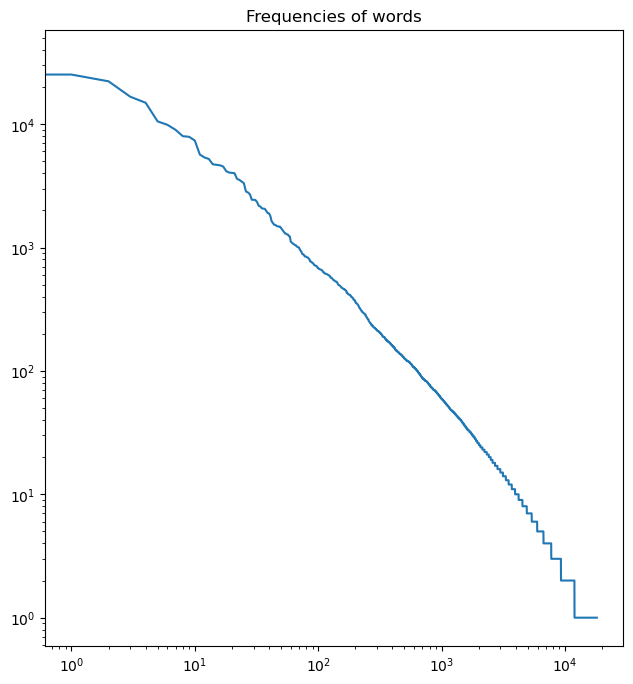

In [ ]:
### ÉCRIVEZ ICI

compteur = Counter(text)

for mot, compte in compteur.most_common(20):
    print(f"{mot}: {compte}")

occurrences = sorted(compteur.values(), reverse=True)

plt.figure(figsize=(8, 8))
plt.plot(occurrences)
plt.xscale('log')
plt.yscale('log')
plt.axis('scaled')

plt.title("Frequencies of words")
plt.show()

Si tout s'est bien passé, vous devriez voir d'après la pente du graphique que, à l'exception des 10 mots les plus fréquents et des mots qui apparaissent moins de 10 fois, 
le nombre d'occurrences du n-ième mot (ou la probabilité du n-ième mot) est approximativement $c/n$ pour une certaine constante $c$. 
C'est ce qu'on appelle la _loi de Zipf_ (elle est purement empirique, mais elle fonctionne assez souvent).





### Un modèle de chaîne de Markov pour générer du texte

Transformons le livre en un modèle de langage qui peut générer du texte (pas tout à fait un ChatGPT, mais tout le monde doit commencer quelque part). Cela fonctionnera comme suit : si les 2 derniers mots de notre texte généré sont, disons,  JUST FAMILY, le modèle les utilisera pour générer aléatoirement le mot suivant, selon les probabilités qu'il a apprises. Si le mot généré est ESTATES, il continuera avec les 2 mots  FAMILY ESTATES et générera le suivant, etc.

Pour que cela fonctionne, nous devons connaître les probabilités, que nous obtiendrons à partir du nombre d'occurrences dans le livre. Faisons-le de manière simple (bien que pas très efficace).

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Définissez (pour le moment) `order = 2`.

Créez un dictionnaire `next_word`. Ses clés seront tous les tuples de `order` mots consécutifs dans `text`, par exemple (si `order` est 2) `( 'JUST', 'FAMILY')`. La valeur `next_word[('JUST', 'FAMILY')]` sera la liste des mots qui suivent immédiatement après ce pair : si `text` contient `[ 'JUST', 'FAMILY', 'ESTATES']` et aussi (à un autre endroit) `[ 'JUST', 'FAMILY', 'PENGUINS']`, alors la liste `next_word[( 'JUST', 'FAMILY')]` devrait contenir à la fois `'ESTATES'` et `'PENGUINS'`. Si `[ 'JUST', 'FAMILY', 'ESTATES']` apparaît deux fois dans `text`, la liste devrait contenir `'ESTATES'` deux fois.
</div>

> Astuces Python : Pour obtenir un dictionnaire vide, utilisez `{}` ou `dict()`. Pour obtenir une liste vide, utilisez `[]` ou `list()`. Si vous voulez simplifier votre code (en n'ayant pas à vérifier si une clé est déjà présente dans `next_word`), vous pouvez utiliser un type spécial de dictionnaire :
> ```python
> from collections import defaultdict
> next_word = defaultdict(list)
> ```
> \
> Ce qu'il fait : si `key` n'est pas encore dans `next_word`, et si vous essayez d'utiliser `next_word[key]`, au lieu de vous donner un message d'erreur, il exécutera `next_word[key] = list()` en coulisses. Vous pouvez donc faire `next_word[key].append(word)` même si `key` apparaît pour la première fois.


In [ ]:
### ÉCRIVEZ ICI

from collections import defaultdict

order = 2
next_word = defaultdict(list)

for i in range(len(text) - order):
    cle = tuple(text[i : i + order])
    mot_suivant = text[i + order]
    
    next_word[cle].append(mot_suivant)

In [ ]:
### EXÉCUTEZ-MOI - UN TEST

assert sorted(next_word['WARN', 'YOU']) == ['CAPTAIN', 'IF', 'SHE', 'THAT'], "next_word (with order = 2) is not correct"

Python a une fonction pour choisir aléatoirement un élément d'une liste :


In [ ]:
### EXÉCUTEZ-MOI 

from random import choice

# ce qui suit renvoie l'un des 'sponge', 'whale', 'penguin', avec des probabilités de 2/4, 1/4, 1/4

for _ in range(50):
    word = choice(['sponge', 'whale', 'penguin', 'sponge'])
    print(word, end=' ')


Maintenant, vous pouvez, enfin, programmer votre propre Tolstoï.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Écrivez une fonction `generate_text(n)` qui imprime un texte contenant `n` mots, selon les probabilités données par `next_word` :

- choisissez la première clé aléatoirement parmi les clés de `next_word` - utilisez `choice(list(next_word.keys()))`
- puis choisissez aléatoirement le mot suivant, en utilisant `choice(next_word[key])`
- continuez jusqu'à ce que vous produisiez `n` mots (gardez-les dans une liste). N'oubliez pas de modifier la clé à chaque étape (en supprimant son premier mot et en ajoutant le nouveau mot).
- enfin, imprimez les mots -  `print(word, end=' ')` le ferra bien
  
Ensuite, générez du texte, par exemple avec `generate_text(200)`. Si vous trouvez le texte trop incohérent, revenez à la cellule où vous avez créé le dictionnaire `next_word`, changez `order` de 2 à 3, et exécutez à nouveau cette cellule. Cela diminuera le niveau de LSD dans votre modèle de Tolstoï.

</div>



In [ ]:
### ÉCRIVEZ ICI

def generate_text(n):
    cle_courante = random.choice(list(next_word.keys()))
    mots_generes = list(cle_courante)
    
    while len(mots_generes) < n:
        if not next_word[cle_courante]:
            break
            
        mot_suivant = random.choice(next_word[cle_courante])
        mots_generes.append(mot_suivant)
        
        cle_courante = cle_courante[1:] + (mot_suivant,)
        
    for word in mots_generes[:n]:
        print(word, end=' ')
    print()

generate_text(200)


ALL USED TO TELL HER SO BORÍS WAS EXPECTING ENTERED THE ROOM UNNOTICED BY HIS WILL AND INEVITABILITY THEMSELVES FROM A GASH IN ITS LAST SNOWS AND STORMS WITH DESPERATE FURY . A YOUNG MAN IS THE ONLY POSSIBLE TO STING WEYROTHER’S VANITY AS A DEFECT BUT AS IT WERE REVIEWED AND OF THE GENERALS BENDING FORWARD RESPECTFULLY . HE WAS READY TO RENDER THE SMALL FIR TREES SCATTERED HERE AND THE AUSTRIAN GENERAL LOOKED DISSATISFIED BUT HAD SUBSEQUENTLY BEEN REMOVED FROM THEIR FACES . IT IS HIS PARTICIPATION . HE DID SO CORRESPOND IN THE EMPEROR’S SEVERITY REGARDING DUELS AT THAT TRIBUNAL HE WILL HAVE TO PROVE TO YOUR GUNS COMMANDED THE COUNTRY OPPOSITE THE SHEVÁRDINO REDOUBT WAS THE DUTY OF EVERY MAN HAD BURNED HIM AND CLOSED HIS EYES AND HE DREW ATTENTION TO HER OCCUPIED HER NOW AND THEN HIS EYEBROWS ABRUPTLY TOUCHED HIS CHEEK RAN BACK AND THE SMOKING SHELL SPUN LIKE A CHILD HER OWN HEART FROM VICE AND FOLLY AND PATRONIZING TALENT AND VIRTUE AND THAT THE VEHICLES WERE GOING ROUND THE SPEAKER . 

## Images de mouvements aléatoires

### Marche aléatoire à effacement de boucles
Implémentons une marche aléatoire à effacement de boucles sur le réseau entier $\mathbb Z^2 \subset \mathbb R^2$. Ce type spécial de marche aléatoire crée un chemin où aucun point n'est visité deux fois.

**Algorithme:**
Le chemin est créé comme une séquence de points du réseau.
- Démarrer à l'origine (0,0) (le chemin contient uniquement le point (0,0))
- À chaque étape:
  1. Déplacer d'une unité dans une direction choisie aléatoirement (haut, bas, gauche ou droite) avec une probabilité égale
  2. Si le nouveau point P est déjà dans notre chemin, effacer la boucle: supprimer tous les points après la première occurrence de P du chemin
  3. Sinon, ajouter P au chemin (dans les deux cas 2. et 3. le chemin se termine maintenant par P)
- Répéter jusqu'à ce que le chemin contienne exactement n points (cela peut prendre de nombreuses itérations car les boucles sont effacées)


<img src="attachment:3fe1dbf2-ff0b-4844-b2de-97f27caa8947.gif" width="400">

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**
Écrire une fonction `loop_erased_random_walk(n, cutoff=10**7)` qui implémente cet algorithme. La fonction doit:
- Renvoyer le chemin sous forme d'une liste de tuples de coordonnées (x,y)
- Utiliser le paramètre `cutoff` comme limite de sécurité: si plus que `cutoff` étapes totales sont effectuées (y compris les étapes effacées), renvoyer le chemin actuel même s'il est plus court que n

Exécuter `loop_erased_random_walk(5000)` et visualiser le chemin résultant à l'aide de matplotlib

</div>

**Conseils d'implémentation:**
```python
# Pour vérifier si un point est dans votre chemin:
if point in path:
    # Obtenir l'index de la première occurrence
    i = path.index(point)
    # Tronquer le chemin pour ne garder que jusqu'à la première occurrence (incluse)
    path = path[:i+1]
# Pour la sélection aléatoire de direction (compatible avec numba si utilisé):
direction = randrange(4)  # ou np.random.choice(4)
```


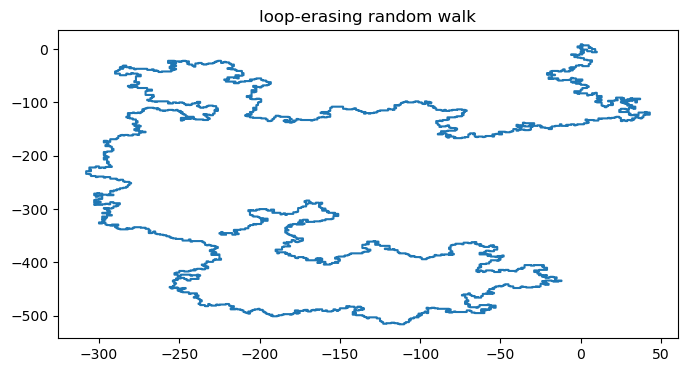

In [ ]:
### ÉCRIVEZ ICI

def loop_erased_random_walk(n, cutoff=10**7):
    path = [(0, 0)]
    total_steps = 0
    
    mouvements = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    
    while len(path) < n and total_steps < cutoff:
        total_steps += 1
        x_actuel, y_actuel = path[-1]
        
        direction = random.randrange(4)
        dx, dy = mouvements[direction]
        nouveau_point = (x_actuel + dx, y_actuel + dy)
        
        if nouveau_point in path:
            i = path.index(nouveau_point)
            path = path[:i+1]
        else:
            path.append(nouveau_point)
            
    return path

chemin = loop_erased_random_walk(5000)

x_coords = [p[0] for p in chemin]
y_coords = [p[1] for p in chemin]

plt.figure(figsize=(8, 4))
plt.plot(x_coords, y_coords, '-')
plt.title("loop-erasing random walk")
plt.show()




### Générateur de labyrinthe aléatoire
Cet exercice utilise les marches aléatoires avec effacement de boucles pour créer des labyrinthes aléatoires comme l'exemple 15 × 15 montré dans l'image :


<img src="attachment:2fa39117-bf48-47df-a8f8-fe512e2b32d0.png" width="250">



**Qu'est-ce qu'un labyrinthe?**

Un labyrinthe de taille n × n est défini comme:
- Une grille carrée [0,n] × [0,n] avec des murs
- La frontière extérieure fait partie des murs
- Tous les points du réseau (les points rouges dans l'image) sont dans les murs
- Entre deux cellules 1×1 quelconques, il existe un chemin sans traverser de murs
- Les murs forment une structure connectée
  
**Le défi**

Pour un grand n, il existe de nombreux labyrinthes n×n possibles. Notre objectif est de les générer aléatoirement avec une probabilité uniforme (chaque labyrinthe possible a la même chance d'être créé).

**L'algorithme de Wilson**

Nous utiliserons l'algorithme de Wilson, qui applique les marches aléatoires à effacement de boucles que vous connaissez déjà:
1. Commencer avec juste la frontière extérieure comme murs
2. Pour chaque point intérieur du réseau (une boucle `for`, dans un ordre arbitraire):
   - Si le point fait déjà partie d'un mur, ne faire rien (et passer au suivant).
   - Sinon, commencer une marche aléatoire à effacement de boucles depuis ce point. Lorsque la marche aléatoire atteint un point qui fait déjà partie d'un mur existant, terminez la marche et ajoutez l'intégralité du chemin  à la structure du mur.



<img src="attachment:7bdc7a41-7d55-4672-a429-1d0162d55dc3.gif" width="300">


<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Créez une fonction `plot_maze(n)` qui génère et affiche un labyrinthe aléatoire n×n et exécutez-la pour n = 50.

</div>

**Conseils d'implémentation**

1. Commencez par le chemin de la bordure:
```python
border = [(0, i) for i in range(n)] + [(i, n) for i in range(n)] \
         + [(n, i) for i in range(n, 0, -1)] + [(i, 0) for i in range(n, -1, -1)]
```
2. Stockez le mur comme une liste de chemins (le premier chemin est `border`, les autres sont les marches aléatoires à effacement de boucles)
3. Suivez les points du mur en utilisant un ensemble:
```
# Initialiser avec les points de la frontière
in_wall = set(border)
# Tester si un point fait partie du mur
if point in in_wall:
    ...
# Ajouter de nouveaux points à in_wall
in_wall |= set(path)
# set1 | set2 est l'union de 2 ensembles en python; set1 |= set2 est un raccourci pour set1 = set1 | set2
```
4. Tracer tous les chemins un par un, avec la même couleur
```python
plot(x, y, 'k')  # Lignes noires
```
5. Il pourrait être judicieux de décomposer votre code en plusieurs fonctions (par exemple, une pour créer une marche aléatoire à effacement de boucles, une pour construire l'ensemble du mur, une pour le traçage).
6. Pas besoin de `njit`.

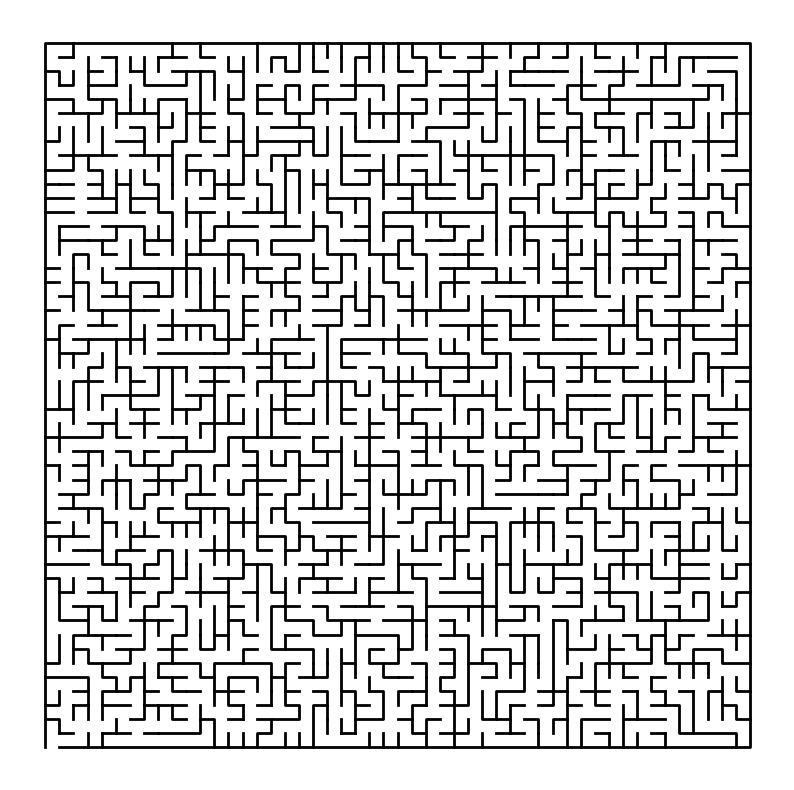

In [ ]:
### ÉCRIVEZ ICI

def generate_lerw(start_point, in_wall, n):
    path = [start_point]
    mouvements = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    
    while path[-1] not in in_wall:
        x_actuel, y_actuel = path[-1]
        
        directions_valides = []
        for dx, dy in mouvements:
            nx, ny = x_actuel + dx, y_actuel + dy
            if 0 <= nx <= n and 0 <= ny <= n:
                directions_valides.append((dx, dy))
                
        dx, dy = random.choice(directions_valides)
        nouveau_point = (x_actuel + dx, y_actuel + dy)
        
        if nouveau_point in path:
            i = path.index(nouveau_point)
            path = path[:i+1]
        else:
            path.append(nouveau_point)
            
    return path

def build_maze(n):
    border = [(0, i) for i in range(n)] + [(i, n) for i in range(n)] \
           + [(n, i) for i in range(n, 0, -1)] + [(i, 0) for i in range(n, 0, -1)]
    
    in_wall = set(border)
    walls_paths = [border]
    
    points_interieurs = [(x, y) for x in range(1, n) for y in range(1, n)]
    random.shuffle(points_interieurs)
    
    for point in points_interieurs:
        if point not in in_wall:
            nouveau_chemin = generate_lerw(point, in_wall, n)
            walls_paths.append(nouveau_chemin)
            in_wall |= set(nouveau_chemin)
            
    return walls_paths

def plot_maze_clean(n):
    walls = build_maze(n)
    
    plt.figure(figsize=(10, 10))
    
    for path in walls:
        x_coords = [p[0] for p in path]
        y_coords = [p[1] for p in path]
        plt.plot(x_coords, y_coords, 'k-', lw=2)
        
    plt.axis('equal')
    plt.axis('off')
    
    plt.show()

plot_maze_clean(50)

## Bonus : quand numba bat numpy 

Dans TP2, nous avons vu, entre autres, un ensemble de Julia "semblable à un dragon". Avec numpy, cela a pris un certain temps à calculer. Avec numba, c'est beaucoup plus rapide - une partie de la raison est que pour la plupart des `z`, nous prenons beaucoup moins que 300 étapes dans la boucle for. Voyez par vous-même :


In [ ]:
### EXÉCUTEZ-MOI

@vectorize('int32(complex128)', nopython=True, target='parallel')
def julia(z):
    for i in range(300):
        z = (3.05 + 0.15j) * z * (1-z)
        if np.abs(z) > 5:
            break
    return i

N = 2000
x = np.linspace(0, 1, N)
y = np.linspace(-0.5, 0.5, N)
x, y = np.meshgrid(x, y)
z = x + y * 1j

steps = julia(z)

plt.figure(figsize=(10, 10)) # create a large image
plt.pcolormesh(x, y, steps, cmap = 'magma')   # creating the heatmap of julia-set array
plt.axis('scaled') # the same scale for the axes
plt.show()

NameError: name 'vectorize' is not defined